# Place-Name Fossils: Andhra Pradesh and Telangana

**Question:** Do Telugu place-name endings (-padu, -guda, -abad and so on) track the AP-Telangana line, and how much does a name alone tell you about where a place is?

**Methods:** ending extraction -> Fisher exact tests with bootstrap CIs and Benjamini-Hochberg correction -> Monte Carlo clustering tests (against random labels, and against random labels shuffled inside each state) -> ridge logistic regression with repeated 10-fold cross-validation (names only, no coordinates) -> smoothed name-score field and its contour (the 'name border') compared with the state line -> permutation test on name 'misfits'.

**Data:** DataMeet railway stations (`stations.json`, 693 distinct places in AP + Telangana) and district boundaries (`india_districts.geojson`).  
**Caveats:** railway stations only, so places not served by rail are missing; ending families are defined by hand (`ending_families_definition.csv`); p-values for the 17 territory tests are not corrected for multiple testing.

### Step 1: Load stations (raw), clean names, assign each station to Telangana or Andhra Pradesh

In [1]:
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import matplotlib.pyplot as plt
from math import comb
from shapely.ops import unary_union
import contourpy

rng = np.random.default_rng(42)
METRIC = "EPSG:7755"

st = gpd.read_file("stations.json")
st = st[st.geometry.notna() & ~st.geometry.is_empty].drop_duplicates("code")

b = gpd.read_file("india_districts.geojson")
b = b[b["district"].notna() & b["st_nm"].isin(["Telangana", "Andhra Pradesh"])].drop_duplicates(["st_nm", "district"])
st = gpd.sjoin(st, b[["st_nm", "district", "geometry"]], predicate="within", how="inner").drop(columns="index_right")
print("Stations inside Telangana + Andhra Pradesh:", len(st))

Stations inside Telangana + Andhra Pradesh: 708


### Step 2: Extract the name ending (suffix family) from each station name

In [2]:
TRAILING = {"halt", "road", "junction", "jn", "cabin", "cantt", "cantonment", "city", "town", "east", "west", "north", "south",
            "central", "colony", "gate", "siding", "cross", "crossing", "rs", "rd", "h", "ps", "bridge", "yard", "goods", "shed", "depot"}
LEADING = {"new", "old"}
FAMILIES = [("gudem", "-gudem"), ("guda", "-guda"), ("cheruvu", "-cheruvu"), ("kunta", "-kunta"), ("padu", "-padu"),
            ("puram", "-puram"), ("pudi", "-pudi"), ("palem", "-palem"), ("palle", "-palle"), ("palli", "-palli"), ("pally", "-palli"),
            ("peta", "-pet(a)"), ("pet", "-pet(a)"), ("varam", "-varam"), ("varram", "-varam"), ("konda", "-konda"), ("kota", "-kota"),
            ("abad", "-abad"), ("nagar", "-nagar"), ("cherla", "-cherla"), ("vada", "-vada/wada"), ("wada", "-vada/wada"),
            ("gutta", "-gutta"), ("gattu", "-gutta"), ("pur", "-pur"), ("ur", "-ur")]

def clean(name):
    t = re.sub(r"[^a-z ]", " ", name.lower()).split()
    orig = t[:]
    while t and t[0] in LEADING: t = t[1:]
    while t and t[-1] in TRAILING: t = t[:-1]
    return t if t else orig

def family(last):
    for suf, label in FAMILIES:
        if last.endswith(suf):
            return label
    return "other"

st["tokens"] = st["name"].apply(clean)
st["root"] = st["tokens"].apply(" ".join)
st["family"] = st["tokens"].apply(lambda t: family(t[-1]))
st = st.drop_duplicates(["root", "district"]).reset_index(drop=True)          # 'Guntur Jn' and 'New Guntur' are one place
st["is_tg"] = (st["st_nm"] == "Telangana").astype(int)
print("Distinct places:", len(st), "| Telangana:", int(st["is_tg"].sum()), "| Andhra Pradesh:", int((1 - st["is_tg"]).sum()))

# families with fewer than 5 stations are folded into 'other'
counts = st["family"].value_counts()
st["family"] = st["family"].where(st["family"].map(counts) >= 5, "other")
print(st["family"].value_counts().to_string())

Distinct places: 693 | Telangana: 226 | Andhra Pradesh: 467
family
other         388
-palli         53
-puram         35
-ur            28
-pet(a)        25
-nagar         19
-padu          17
-palle         17
-pur           16
-guda          13
-varam         12
-konda         11
-pudi          11
-abad          10
-palem         10
-cheruvu       10
-cherla        10
-vada/wada      8


### Step 3: Which endings are genuinely tied to one state? (Fisher exact test, bootstrap CI, Benjamini-Hochberg)

In [3]:
def fisher_two_sided(a, b_, c, d):
    n1, n2, k, N = a + b_, c + d, a + c, a + b_ + c + d
    pmf = lambda x: comb(n1, x) * comb(n2, k - x) / comb(N, k)
    p0 = pmf(a)
    return min(1.0, sum(pmf(x) for x in range(max(0, k - n2), min(k, n1) + 1) if pmf(x) <= p0 * (1 + 1e-9)))

fams = [f for f in st["family"].unique() if f != "other"]
fam_idx = st["family"].map({f: i for i, f in enumerate(fams)}).fillna(-1).astype(int).values
is_tg = st["is_tg"].values
n_tg, n_ap = is_tg.sum(), (1 - is_tg).sum()

def log2_or(tg_k, ap_k, tg_tot, ap_tot):
    return np.log2(((tg_k + .5) / (tg_tot - tg_k + .5)) / ((ap_k + .5) / (ap_tot - ap_k + .5)))

B = 2000
boot = np.empty((B, len(fams)))
for bi in range(B):
    s = rng.integers(0, len(st), len(st))
    tg_s, ap_s = is_tg[s].sum(), (1 - is_tg[s]).sum()
    for fi in range(len(fams)):
        m = fam_idx[s] == fi
        boot[bi, fi] = log2_or((m & (is_tg[s] == 1)).sum(), (m & (is_tg[s] == 0)).sum(), tg_s, ap_s)

rows = []
for fi, f in enumerate(fams):
    m = fam_idx == fi
    a, c = int((m & (is_tg == 1)).sum()), int((m & (is_tg == 0)).sum())
    rows.append({"ending": f, "n_telangana": a, "n_andhra": c, "log2_odds_ratio_TG_vs_AP": log2_or(a, c, n_tg, n_ap),
                 "ci_low": np.percentile(boot[:, fi], 2.5), "ci_high": np.percentile(boot[:, fi], 97.5),
                 "p_value": fisher_two_sided(a, n_tg - a, c, n_ap - c)})
tests = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
m_ = len(tests); order = np.argsort(tests["p_value"].values)
bh = tests["p_value"].values[order] * m_ / (np.arange(m_) + 1)
bh = np.minimum.accumulate(bh[::-1])[::-1]
tests.loc[order, "p_adj_BH"] = np.minimum(bh, 1)
tests["significant_5pct"] = tests["p_adj_BH"] < 0.05
print(tests.round(4).to_string(index=False))

    ending  n_telangana  n_andhra  log2_odds_ratio_TG_vs_AP  ci_low  ci_high  p_value  p_adj_BH  significant_5pct
    -nagar           16         3                    3.3789  2.0287   6.0956   0.0000    0.0001              True
     -guda           12         1                    4.1798  2.3791   6.2973   0.0000    0.0001              True
     -abad           10         0                    5.5029  4.3309   6.2605   0.0000    0.0001              True
    -palli           32        21                    1.7950  0.9752   2.6512   0.0000    0.0001              True
     -padu            0        17                   -4.1373 -4.7405  -3.2871   0.0024    0.0083              True
      -pur           11         5                    2.1659  0.7949   3.9452   0.0047    0.0132              True
    -palle            1        16                   -2.4578 -4.5433  -0.8556   0.0166    0.0403              True
  -cheruvu            0        10                   -3.3781 -4.1339  -2.2846   0.0353   

### Step 4: Do endings form territories? (same-ending stations vs random labels, Monte Carlo)

In [4]:
pts = st.to_crs(METRIC)
xy = np.column_stack([pts.geometry.x, pts.geometry.y])
D = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1)) / 1000          # km
np.fill_diagonal(D, np.inf)

def mean_nn(idx):
    return D[np.ix_(idx, idx)].min(axis=1).mean()

state_groups = [np.where(is_tg == 1)[0], np.where(is_tg == 0)[0]]
P = 2000
terr = []
for fi, f in enumerate(fams):
    idx = np.where(fam_idx == fi)[0]
    if len(idx) < 8:
        continue
    obs = mean_nn(idx)
    null_all = np.array([mean_nn(rng.choice(len(st), len(idx), replace=False)) for _ in range(P)])
    # null 2: keep the Telangana/Andhra split of this ending, shuffle only inside each state
    k_tg = int(is_tg[idx].sum()); k_ap = len(idx) - k_tg
    null_in = np.array([mean_nn(np.concatenate([rng.choice(state_groups[0], k_tg, replace=False),
                                                rng.choice(state_groups[1], k_ap, replace=False)])) for _ in range(P)])
    terr.append({"ending": f, "n": len(idx), "mean_nn_km": obs, "random_mean_km": null_all.mean(),
                 "p_vs_random": (np.sum(null_all <= obs) + 1) / (P + 1),
                 "random_within_state_km": null_in.mean(), "p_beyond_state": (np.sum(null_in <= obs) + 1) / (P + 1)})
territory = pd.DataFrame(terr).sort_values("p_vs_random").round(4)
print(territory.to_string(index=False))

    ending  n  mean_nn_km  random_mean_km  p_vs_random  random_within_state_km  p_beyond_state
  -cheruvu 10     41.6824         95.4707       0.0045                 75.6530          0.0290
     -padu 17     38.7998         66.3177       0.0065                 50.8013          0.0935
     -guda 13     53.5761         79.3530       0.0555                 56.1780          0.4368
   -cherla 10     63.4792         95.4083       0.0750                 96.0479          0.0685
     -abad 10     62.6039         95.3242       0.0770                 48.1362          0.8726
    -palem 10     64.6030         95.3091       0.0780                 94.3726          0.0600
    -palli 53     26.8830         30.9027       0.1189                 29.6497          0.1989
    -palle 17     56.5346         65.9136       0.2304                 61.2681          0.3353
-vada/wada  8     93.3291        110.8262       0.2879                113.2759          0.2394
     -pudi 11     79.8727         88.8479       0.

### Step 5: Predict the state from the name alone (ridge logistic regression, repeated 10-fold cross-validation)

In [5]:
X = np.zeros((len(st), len(fams) + 1)); X[:, 0] = 1
for i, f in enumerate(fam_idx):
    if f >= 0:
        X[i, f + 1] = 1
y = is_tg.astype(float)

def fit_logit(X, y, lam=1.0, iters=25):
    w = np.zeros(X.shape[1]); R = lam * np.eye(X.shape[1]); R[0, 0] = 0          # intercept unpenalised
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ w))
        H = X.T @ (X * (p * (1 - p))[:, None]) + R
        step = np.linalg.solve(H, X.T @ (y - p) - R @ w)
        w += step
        if np.abs(step).max() < 1e-8:
            break
    return w

def auc(score, label):
    r = pd.Series(score).rank().values
    n1, n0 = label.sum(), (1 - label).sum()
    return (r[label == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

# stratified 10-fold, repeated 20 times. (Leave-one-out gives a misleading AUC with one-hot name features: removing a
# station's own label from its group makes held-out scores rank backwards, so k-fold is used instead.)
REPS, K = 20, 10
oof = np.zeros((REPS, len(st)))
fold_auc, fold_acc = [], []
for r_ in range(REPS):
    fold = np.empty(len(st), dtype=int)
    for cls in (0, 1):
        idx = rng.permutation(np.where(y == cls)[0]); fold[idx] = np.arange(len(idx)) % K
    for k_ in range(K):
        te = fold == k_
        w = fit_logit(X[~te], y[~te])
        oof[r_, te] = 1 / (1 + np.exp(-X[te] @ w))
        fold_auc.append(auc(oof[r_, te], y[te])); fold_acc.append(((oof[r_, te] >= 0.5) == y[te]).mean())
oof_p = oof.mean(axis=0)
st["name_score_TG"] = oof_p                      # probability the name 'looks Telangana', from models that never saw this station

pred = (oof_p >= 0.5).astype(int)
majority = max(y.mean(), 1 - y.mean())
nn5 = np.argsort(D, axis=1)[:, :5]
acc_xy = ((y[nn5].mean(axis=1) >= 0.5).astype(int) == y).mean()       # context: location alone (5 nearest stations vote)
tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
print(f"Names alone: accuracy {np.mean(fold_acc):.1%} | AUC {np.mean(fold_auc):.3f} (mean of {len(fold_auc)} CV folds, fold-to-fold SD {np.std(fold_auc):.3f})")
print(f"Baselines: always guess Andhra Pradesh {majority:.1%} | location only (5 nearest stations) {acc_xy:.1%}")
print(f"Out-of-fold predictions: Telangana found {tp}/{tp + fn} ({tp / (tp + fn):.0%}), Andhra correct {tn}/{tn + fp} ({tn / (tn + fp):.0%}), balanced accuracy {(tp / (tp + fn) + tn / (tn + fp)) / 2:.1%}")
print(f"AUC across CV folds: mean {np.mean(fold_auc):.3f}, 5th to 95th percentile {np.percentile(fold_auc, 5):.3f} to {np.percentile(fold_auc, 95):.3f}  (0.5 = no information, 1 = perfect)")

Names alone: accuracy 74.7% | AUC 0.697 (mean of 200 CV folds, fold-to-fold SD 0.053)
Baselines: always guess Andhra Pradesh 67.4% | location only (5 nearest stations) 99.3%
Out-of-fold predictions: Telangana found 81/226 (36%), Andhra correct 437/467 (94%), balanced accuracy 64.7%
AUC across CV folds: mean 0.697, 5th to 95th percentile 0.613 to 0.773  (0.5 = no information, 1 = perfect)


### Step 6: Where is the 'name border'? Smooth the name score over space and find its 50% contour

In [6]:
tg_u = unary_union(b[b["st_nm"] == "Telangana"].to_crs(METRIC).geometry)
ap_u = unary_union(b[b["st_nm"] == "Andhra Pradesh"].to_crs(METRIC).geometry)
region = unary_union([tg_u, ap_u])
state_line = tg_u.boundary.intersection(ap_u.buffer(1000))                    # the AP-Telangana border only
print(f"AP-Telangana border length: {state_line.length / 1000:.0f} km")

STEP, H = 10000, 50000                                                       # 10 km grid, 50 km smoothing
gx = np.arange(xy[:, 0].min() - 50000, xy[:, 0].max() + 50000, STEP)
gy = np.arange(xy[:, 1].min() - 50000, xy[:, 1].max() + 50000, STEP)
GX, GY = np.meshgrid(gx, gy)
cells = np.column_stack([GX.ravel(), GY.ravel()])
inside = gpd.GeoSeries(gpd.points_from_xy(cells[:, 0], cells[:, 1])).within(region).values
Dg = np.sqrt(((cells[:, None, :] - xy[None, :, :]) ** 2).sum(-1))
near = Dg.min(axis=1) < 60000                                               # only trust cells near some station
use = inside & near
Wk = np.exp(-0.5 * (Dg / H) ** 2)

def contour_distance(weights_per_station, values, level):
    num, den = Wk @ (weights_per_station * values), Wk @ weights_per_station
    field = np.where(use & (den > 1e-9), num / np.maximum(den, 1e-9), np.nan).reshape(GX.shape)
    lines = contourpy.contour_generator(gx, gy, np.ma.masked_invalid(field)).lines(level)
    lines = [l for l in lines if len(l) > 1]
    if not lines:
        return None, (field, [])
    pts_ = np.vstack(lines)
    d = gpd.GeoSeries(gpd.points_from_xy(pts_[:, 0], pts_[:, 1])).distance(state_line).values / 1000
    return (np.median(d), np.percentile(d, 90), len(pts_)), (field, lines)

ones = np.ones(len(st))
LEVEL = 0.5 * (oof_p[y == 1].mean() + oof_p[y == 0].mean())              # where the name style flips from Andhra-typical to Telangana-typical
print(f"Name-score level used for the border: {LEVEL:.3f} (mean score: Telangana stations {oof_p[y == 1].mean():.3f}, Andhra stations {oof_p[y == 0].mean():.3f})")
res_names, (field_names, lines_names) = contour_distance(ones, oof_p, LEVEL)
res_truth, (field_truth, lines_truth) = contour_distance(ones, y, 0.5)
print(f"Calibration: contour of the TRUE state labels lies a median {res_truth[0]:.1f} km from the state line")
if res_names is None:
    print("No name border found: the smoothed name score never crosses the level")
else:
    print(f"Name border (names only): median {res_names[0]:.1f} km from the state line, 90th percentile {res_names[1]:.1f} km")

meds = []
for _ in range(300):
    wts = np.bincount(rng.integers(0, len(st), len(st)), minlength=len(st)).astype(float)
    r, _ = contour_distance(wts, oof_p, LEVEL)
    if r is not None:
        meds.append(r[0])
print(f"Bootstrap 95% range of the median distance: {np.percentile(meds, 2.5):.1f} to {np.percentile(meds, 97.5):.1f} km  (n = {len(meds)} resamples)")

AP-Telangana border length: 717 km
Name-score level used for the border: 0.349 (mean score: Telangana stations 0.413, Andhra stations 0.284)
Calibration: contour of the TRUE state labels lies a median 12.2 km from the state line
Name border (names only): median 37.8 km from the state line, 90th percentile 71.9 km
Bootstrap 95% range of the median distance: 22.3 to 112.7 km  (n = 300 resamples)


### Step 7: Misfits: stations whose names point to the other state (leave-one-out probability of own state < 25%)

In [7]:
own_p = np.where(is_tg == 1, oof_p, 1 - oof_p)
st["prob_own_state"] = own_p
st["misfit"] = own_p < 0.25
dist_line = gpd.GeoSeries(pts.geometry.values).distance(state_line).values / 1000
st["km_to_state_line"] = dist_line
mis = st["misfit"].values
obs = dist_line[mis].mean()
null = np.array([dist_line[rng.permutation(mis)].mean() for _ in range(5000)])
print(f"Misfits: {int(mis.sum())} of {len(st)} | mean distance to the state line {obs:.0f} km vs {dist_line.mean():.0f} km for all stations | "
      f"p(closer than chance) = {(np.sum(null <= obs) + 1) / 5001:.3f}")
print(st[st["misfit"]].groupby("st_nm").size().to_string())
print(st[st["misfit"]].sort_values("prob_own_state")[["name", "district", "st_nm", "family", "prob_own_state", "km_to_state_line"]].round(2).head(15).to_string(index=False))

Misfits: 20 of 693 | mean distance to the state line 91 km vs 134 km for all stations | p(closer than chance) = 0.012
st_nm
Andhra Pradesh     4
Telangana         16
                 name             district     st_nm     family  prob_own_state  km_to_state_line
          NAGALAPALLE           Sangareddy Telangana     -palle            0.09            145.76
          Tadakalpudi Bhadradri Kothagudem Telangana      -pudi            0.12             41.33
            ERRUPALEM              Khammam Telangana     -palem            0.13              1.32
          REPALLIWADA        Komaram Bheem Telangana -vada/wada            0.14            220.24
     TONDALAGOPAVARAM              Khammam Telangana     -varam            0.16              3.78
      KUCHAVARAM HALT                Medak Telangana     -varam            0.16            152.70
RAMAKRISHNAPURAM GATE   Medchal Malkajgiri Telangana     -puram            0.16            125.64
            Aswapuram Bhadradri Kothagudem Telanga

### Step 8: Chart: which endings tell the states apart, and how much do names add?

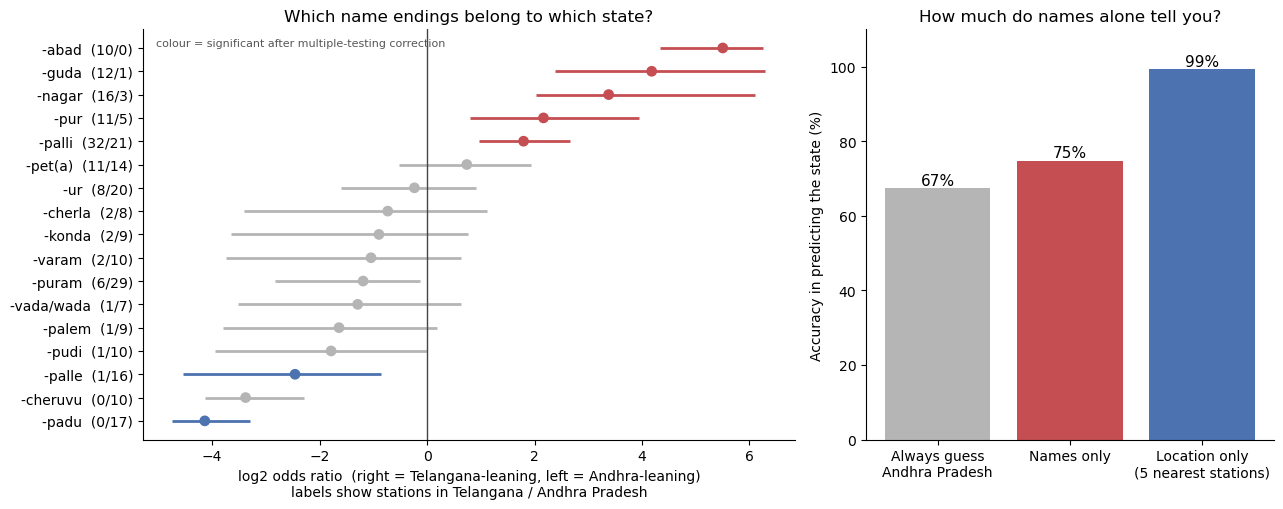

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
t = tests.sort_values("log2_odds_ratio_TG_vs_AP")
cols = ["#C44E52" if (sig and v > 0) else "#4C72B0" if sig else "#b5b5b5" for sig, v in zip(t["significant_5pct"], t["log2_odds_ratio_TG_vs_AP"])]
ax[0].hlines(range(len(t)), t["ci_low"], t["ci_high"], color=cols, lw=2)
ax[0].scatter(t["log2_odds_ratio_TG_vs_AP"], range(len(t)), color=cols, s=45, zorder=3)
ax[0].axvline(0, color="#444", lw=1)
ax[0].set_yticks(range(len(t))); ax[0].set_yticklabels([f"{e}  ({a}/{c})" for e, a, c in zip(t["ending"], t["n_telangana"], t["n_andhra"])])
ax[0].set_xlabel("log2 odds ratio  (right = Telangana-leaning, left = Andhra-leaning)\nlabels show stations in Telangana / Andhra Pradesh")
ax[0].set_title("Which name endings belong to which state?", fontsize=12)
ax[0].text(0.02, 0.96, "colour = significant after multiple-testing correction", transform=ax[0].transAxes, fontsize=8, color="#555")
bars = [("Always guess\nAndhra Pradesh", majority), ("Names only", np.mean(fold_acc)), ("Location only\n(5 nearest stations)", acc_xy)]
ax[1].bar([x[0] for x in bars], [x[1] * 100 for x in bars], color=["#b5b5b5", "#C44E52", "#4C72B0"])
for i, (_, v) in enumerate(bars):
    ax[1].text(i, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=11)
ax[1].set_ylim(0, 110); ax[1].set_ylabel("Accuracy in predicting the state (%)")
ax[1].set_title("How much do names alone tell you?", fontsize=12)
for a_ in ax:
    a_.spines["top"].set_visible(False); a_.spines["right"].set_visible(False)
plt.tight_layout(); plt.savefig("place_name_chart.png", dpi=150)

### Step 9: Interactive map

In [9]:
import branca.colormap as cm
sll = st.copy()
score_cm = cm.LinearColormap(["#2166ac", "#f7f7f7", "#b2182b"], vmin=0, vmax=max(0.8, sll["name_score_TG"].max()))
score_cm.caption = "Name style: blue = Andhra-typical ending, red = Telangana-typical ending (out-of-fold score)"
to_ll = lambda geom: gpd.GeoSeries([geom], crs=METRIC).to_crs("EPSG:4326").iloc[0]

m = folium.Map(location=[16.4, 79.4], zoom_start=6.4, tiles=None)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}", attr="Esri", name="Base map").add_to(m)

# state fills + labels first, so every other layer draws on top of them
STATE_FILL = {"Telangana": "#f5c48a", "Andhra Pradesh": "#a9d3b4"}
STATE_EDGE = {"Telangana": "#a64d00", "Andhra Pradesh": "#14612f"}
states_ll = b.dissolve(by="st_nm", as_index=False)[["st_nm", "geometry"]].copy()
states_ll["geometry"] = states_ll.geometry.simplify(0.003)
folium.GeoJson(states_ll, name="States (filled)",
               style_function=lambda f: {"fillColor": STATE_FILL[f["properties"]["st_nm"]], "color": STATE_EDGE[f["properties"]["st_nm"]], "weight": 3.5, "fillOpacity": 0.6},
               tooltip=folium.GeoJsonTooltip(["st_nm"], ["State:"])).add_to(m)
dist_ll = b[["district", "st_nm", "geometry"]].copy(); dist_ll["geometry"] = dist_ll.geometry.simplify(0.003)
folium.GeoJson(dist_ll, name="District boundaries", style_function=lambda f: {"color": "#ffffff", "weight": 0.9, "fillOpacity": 0, "opacity": 0.9}).add_to(m)
for _, r_ in states_ll.iterrows():
    p_ = r_.geometry.representative_point()
    folium.Marker([p_.y, p_.x], icon=folium.DivIcon(html=(
        f'<div style="transform:translate(-50%,-50%);font:700 17px sans-serif;letter-spacing:3px;white-space:nowrap;'
        f'color:{STATE_EDGE[r_["st_nm"]]};opacity:0.55;pointer-events:none">{r_["st_nm"].upper()}</div>'))).add_to(m)

def tip(r):
    return (f"<b>{r['name']}</b><br>{r['district']}, {r['st_nm']}<br>Ending: {r['family']}<br>"
            f"Name style score: {r['name_score_TG']:.2f}" + ("<br><b>Misfit: name looks like the other state</b>" if r["misfit"] else ""))

g1 = folium.FeatureGroup(name="Stations by name style score", show=True)
for _, r in sll.iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=2.5, color="#222222", weight=0.5, fill=True,
                        fill_color=score_cm(r["name_score_TG"]), fill_opacity=0.95, tooltip=folium.Tooltip(tip(r))).add_to(g1)
g1.add_to(m)

g2 = folium.FeatureGroup(name="Misfits (name points to the other state)", show=True)
for _, r in sll[sll["misfit"]].iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=5.5, color="#000000", weight=1.8, fill=False, tooltip=folium.Tooltip(tip(r))).add_to(g2)
g2.add_to(m)

sig_endings = tests.loc[tests["significant_5pct"] | (tests["ending"] == "-cheruvu"), "ending"].tolist()
palette = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#f781bf", "#17becf"]
for e, c in zip(sig_endings, palette):
    g = folium.FeatureGroup(name=f"Ending {e}", show=False)
    for _, r in sll[sll["family"] == e].iterrows():
        folium.CircleMarker([r.geometry.y, r.geometry.x], radius=3.2, color="#222222", weight=0.5, fill=True, fill_color=c, fill_opacity=0.95, tooltip=folium.Tooltip(tip(r))).add_to(g)
    g.add_to(m)

folium.GeoJson(to_ll(state_line).__geo_interface__, name="AP-Telangana border", style_function=lambda f: {"color": "#111", "weight": 2, "dashArray": "6,5"}).add_to(m)
nb_lines = unary_union([__import__("shapely.geometry", fromlist=["LineString"]).LineString(l) for l in lines_names])
folium.GeoJson(to_ll(nb_lines).__geo_interface__, name="Name border (smoothed 50% contour)", style_function=lambda f: {"color": "#d7191c", "weight": 3}).add_to(m)
score_cm.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save("place_name_map.html")

### Step 10: Save processed outputs

In [10]:
out = st.drop(columns=["tokens"]).copy()
out["lon"], out["lat"] = out.geometry.x.round(5), out.geometry.y.round(5)
out.drop(columns="geometry").round({"name_score_TG": 3, "prob_own_state": 3, "km_to_state_line": 1}).to_csv("station_name_features.csv", index=False)
out.round({"name_score_TG": 3, "prob_own_state": 3, "km_to_state_line": 1}).to_file("station_name_features.geojson", driver="GeoJSON")
tests.round(4).merge(territory, on="ending", how="left").to_csv("ending_tests.csv", index=False)
pd.DataFrame(FAMILIES, columns=["name_ends_with", "ending_family"]).to_csv("ending_families_definition.csv", index=False)
gpd.GeoDataFrame({"layer": ["AP-Telangana border", "Name border (smoothed 50% contour)"],
                  "geometry": [to_ll(state_line), to_ll(nb_lines)]}, crs="EPSG:4326").to_file("borders_state_vs_name.geojson", driver="GeoJSON")
print("Saved outputs")

Saved outputs
